&nbsp;

&nbsp;

# HN-score transcript bottom5p selection

- [./02_1_HNscore_transcript_fantabio.ipynb](./02_1_HNscore_transcript_fantabio.ipynb) で、全ての HN-score を算出した transcript と CRE の対応を作成したので、これを元に、bottom5p に対応する transcript-cre を選抜する

In [1]:
import os
import datetime
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl
import matplotlib.pyplot as plt
from upsetplot import UpSet, from_contents
from IPython.display import display


os.environ["POLARS_MAX_THREADS"] = "16"

In [2]:
VERSION = datetime.datetime.now().strftime("%y%m")
Execute_date = datetime.datetime.now().strftime("%y%m%d")
print(f"Execute Date: {Execute_date}")

Execute Date: 261001


&nbsp;

&nbsp;

&nbsp;

## 1． All HN-score calculated Transcript - CRE pairs

- 公共遺伝子発現データ (bulk RNA-seq) のメタ解析 によって得られた transcriptsのデータを使用する
- このデータには、CRE と対応づいていない transcript も含まれていることに注意
- [./02_1_HNscore_transcript_fantabio.ipynb](./02_1_HNscore_transcript_fantabio.ipynb) によって作成した対応表を使用する

In [3]:
HNscore_transcript_all_fantabio = pl.read_parquet(
    f"../../out/fantabio/parquet_file/HNscore_transcript_all_fantabio_v261001.parquet"
)

pl.Config.set_tbl_rows(4)
display(HNscore_transcript_all_fantabio)

transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000309758.6""",352,17,37,335,232,4,15,228,"""HSPA6""","""HGNC:5239""","""protein_coding""","""ENSG00000173110.8""","[""basic"", ""Ensembl_canonical"", … ""CCDS""]","""+""",6,null,null,null,"""ensembl_havana_gene_homo_sapie…","[""MANE_select""]",1,"""FCHS_28105""","""chr1""",161523745,"""161524487""","""cp1@HSPA6""","[""GQ891451""]","""0""",53,"[{""EH38E2843853"",""pELS""}, {""EH38E2843855"",""PLS""}, {""EH38E3981533"",""pELS""}]","[{""STAG2"",4103,[{""SRX9975614"",4103}, {""SRX9975613"",3500}, {""SRX26159208"",562}]}, {""HSF1"",4038,[{""SRX16646095"",4038}, {""SRX16646111"",3572}, … {""SRX13845684"",554}]}, … {""GABPA"",500,[{""SRX2635792"",500}]}]","[{""HS_00013400"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, {""HS_00013401"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, … {""HS_00013403"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]",null,null,0.982111,"""PLA""","""204,0,0""","""red"""
"""ENST00000309758.6""",352,17,37,335,232,4,15,228,"""HSPA6""","""HGNC:5239""","""protein_coding""","""ENSG00000173110.8""","[""basic"", ""Ensembl_canonical"", … ""CCDS""]","""+""",6,null,null,null,"""ensembl_havana_gene_homo_sapie…","[""MANE_select""]",1,"""FCHS_28106""","""chr1""",161524161,"""161524546""","""cp4@HSPA6""","[""ENST00000309758.6"", ""NM_002155.5"", … ""AK295212""]","""0""",0,"[{""EH38E2843855"",""PLS""}]","[{""HSF1"",4038,[{""SRX16646095"",4038}, {""SRX16646111"",3572}, … {""SRX3322007"",560}]}, {""CTCF"",3651,[{""SRX10975999"",3651}, {""SRX10976007"",2920}, … {""SRX13551280"",511}]}, … {""MED12"",511,[{""SRX10852993"",511}]}]","[{""HS_00013400"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, {""HS_00013401"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, … {""HS_00013403"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]","[{""hg19::chr1:161494328..161494332,+;hg_6264.1"",""p1@HSPA6""}]",null,0.943234,"""PLA""","""204,0,0""","""red"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000549545.1""",11,265,130,-254,8,174,69,-166,"""COQ10A""","""HGNC:26515""","""retained_intron""","""ENSG00000135469.15""",[],"""+""",0,null,null,null,"""ensembl_havana_gene_homo_sapie…",null,0,"""FCHS_96252""","""chr12""",56268140,"""56268446""","""cp6@COQ10A""","[""ENST00000549545.1""]","""-23""",-23,"[{""EH38E4064794"",""pELS""}]",null,"[{""HS_00173371"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, {""HS_02053667"",""Thyroid Gland"",""Thyroid gland"",""Others"",""gkmSVM""}]",null,null,-0.368421,"""ELA""","""255,202,74""","""yellow"""
"""ENST00000560179.2""",11,272,123,-261,5,181,65,-176,"""ETFA""","""HGNC:3481""","""retained_intron""","""ENSG00000140374.18""","[""RNA_Seq_supported_partial""]","""-""",1,null,null,null,"""ensembl_havana_gene_homo_sapie…","[""RNA-Seq supported partial""]",1,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 2. bottom5p transcripts (all datasets)

- related notebook: [../01_HNscore/01_2_HNscore_transcript_gencode.ipynb](../01_HNscore/01_2_HNscore_transcript_gencode.ipynb)
- 収集した全ての bulk RNA-seq から計算した HN-score のデータから選抜したデータを使用する

In [4]:

bottom5p_transcripts_list = pl.read_csv(
    "../../Data/HNscore/HNscore_transcript/HNscore_gencode_2610/HN2_bottom_5_percent_transcripts.tsv",
    separator="\t",
    n_threads=16
)


pl.Config.set_tbl_rows(4)
print(bottom5p_transcripts_list.select("transcript_id").n_unique())
display(bottom5p_transcripts_list)

26643


transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UPcount+1 / DOWNcount+1 2,log2(UPcount+1 / DOWNcount+1) 2
str,i64,i64,i64,i64,f64,f64
"""ENST00000831501.1""",44,92,270,-48,0.483871,-1.047306
"""ENST00000634833.2""",39,87,280,-48,0.454545,-1.137504
…,…,…,…,…,…,…
"""ENST00000426094.5""",11,265,130,-254,0.045113,-4.47032
"""ENST00000560179.2""",11,272,123,-261,0.043956,-4.507795


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 3. `JOIN` Dataframe

In [5]:
bottom5p_fantabio = bottom5p_transcripts_list.select("transcript_id").unique().join(
    HNscore_transcript_all_fantabio,
    on="transcript_id",
    how="inner",
    coalesce=True
).sort(
    "HN2",
    descending=True
).filter(
    pl.col("cre_id").is_not_null()
)

pl.Config.set_tbl_rows(2)
print(f"bottom5p_transcripts_all ensembl transcript count: {bottom5p_transcripts_list.select('transcript_id').n_unique()}")
print(f"bottom5p_fantabio ensembl transcript count (has fantabio CRE annotation): {bottom5p_fantabio.select('transcript_id').n_unique()}")
print(f"bottom5p_fantabio cre count: {bottom5p_fantabio.select('cre_id').n_unique()}")
print(f"bottom5p_fantabio transcript-CRE pairs count: {bottom5p_fantabio.select(['transcript_id', 'cre_id']).n_unique()}")
display(bottom5p_fantabio)


bottom5p_transcripts_all ensembl transcript count: 26643
bottom5p_fantabio ensembl transcript count (has fantabio CRE annotation): 22185
bottom5p_fantabio cre count: 34360
bottom5p_fantabio transcript-CRE pairs count: 66960


transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000834029.1""",69,117,220,-48,47,56,148,-9,"""EXO5-DT""","""HGNC:55647""","""lncRNA""","""ENSG00000238287.2""","[""basic"", ""Ensembl_canonical"", … ""TAGENE""]","""-""",4,"""URS0002A1647B""","""ENSEMBL_GENCODE""",null,"""havana_homo_sapiens""","[""CLS3 project""]",1,"""FCHS_11684""","""chr1""",40508315,"""40508650""","""cp5@EXO5""","[""ENST00000925740.1""]","""0""",-63,"[{""EH38E2805480"",""PLS""}]","[{""ZNF687"",3399,[{""SRX10478566"",3399}, {""SRX10478565"",2503}]}, {""TCF7"",2966,[{""SRX10774913"",2966}, {""SRX10774914"",2622}]}, … {""NFATC1"",515,[{""SRX335071"",515}]}]","[{""HS_00004908"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}, {""HS_00004909"",""Foreskin Melanocyte Primary Cells skin01"",""Prepuce"",""Skin"",""SVM""}, … {""HS_00004912"",""Small Intestine"",""Small intestine"",""Intestine"",""SVM""}]","[{""hg19::chr1:40974317..40974346,-;hg_11928.1"",""hg_11928.1""}]",null,0.952663,"""ELA""","""255,202,74""","""yellow"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000549545.1""",11,265,130,-254,8,174,69,-166,"""COQ10A""","""HGNC:26515""","""retained_intron""","""ENSG00000135469.15""",[],"""+""",0,null,null,null,"""ensembl_havana_gene_homo_sapie…",null,0,"""FCHS_96252""","""chr12""",56268140,"""56268446""","""cp6@COQ10A""","[""ENST00000549545.1""]","""-23""",-23,"[{""EH38E4064794"",""pELS""}]",null,"[{""HS_00173371"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, {""HS_02053667"",""Thyroid Gland"",""Thyroid gland"",""Others"",""gkmSVM""}]",null,null,-0.368421,"""ELA""","""255,202,74""","""yellow"""


In [6]:
bottom5p_fantabio.write_parquet(
    f"../../out/fantabio/parquet_file/bottom5p_transcript_fantabio_v{Execute_date}.parquet",
    compression_level=9
)

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 4. No Proximal CRE Transcripts

- fanta.bio CRE annotation (± 500 bp) がない transcript を取得

In [7]:
# fanta.bio CRE annotation (± 500 bp) がない transcript を可視化
bottom5p_fantabio_no_cre = bottom5p_transcripts_list.select("transcript_id").unique().join(
    HNscore_transcript_all_fantabio,
    on="transcript_id",
    how="inner",
    coalesce=True
).sort(
    "HN2",
    descending=True
).filter(
    pl.col("cre_id").is_null() # Point: 近傍に fantabio CRE がない
)

# Drop columns that are null on every row (CRE fields stay null when cre_id is null)
bottom5p_fantabio_no_cre = bottom5p_fantabio_no_cre.select(
    [
        name
        for name, n_null in zip(
            bottom5p_fantabio_no_cre.columns,
            bottom5p_fantabio_no_cre.null_count().row(0),
        )
        if n_null < bottom5p_fantabio_no_cre.height
    ]
)

bottom5p_fantabio_no_cre.write_parquet(
    f"../../out/fantabio/no_proximal_cre_transcirpt_list/bottom5p_transcript_no_cre_v{Execute_date}.parquet",
    compression_level=9
)

display(bottom5p_fantabio_no_cre)

transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32
"""ENST00000535641.5""",84,132,190,-48,58,64,129,-6,"""ANAPC5""","""HGNC:15713""","""retained_intron""","""ENSG00000089053.14""",[],"""-""",0,null,null,"[""polya_signal"", ""polya_site""]","""ensembl_havana_gene_homo_sapie…",null,0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000560179.2""",11,272,123,-261,5,181,65,-176,"""ETFA""","""HGNC:3481""","""retained_intron""","""ENSG00000140374.18""","[""RNA_Seq_supported_partial""]","""-""",1,null,null,null,"""ensembl_havana_gene_homo_sapie…","[""RNA-Seq supported partial""]",1


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 5. `ChIP-Atlas` Enrichment analysis で実行する用のBEDファイル作成

In [8]:
# https://data.fanta.bio/cre/v1.2.1/00README_v1.2.1.txt
fantabio_bed = pl.read_csv(
    "../../Data/Database/fantabio/human-CREv1.2.1.hg38.cre-peaks.bed",
    separator="\t",
    n_threads=16,
    has_header=False,
    new_columns=[
        "cre_chrom",
        "cre_chrom_start",
        "cre_chrom_end",
        "cre_id",
        "score",
        "strand",
        "thickStart",
        "thickEnd",
        "itemRgb",
        "cre_name",
        "pooled_cre_scores"
    ]
).with_columns(
    pl.col("pooled_cre_scores").str.extract(r"directionality:([^|]+)", 1).cast(pl.Float64, strict=False).alias("directionality"),
    pl.col("pooled_cre_scores").str.extract(r"class:([^|]+)", 1).alias("fantabio_cre_class"),
)

# Map exact RGB strings to human-readable names
rgb_to_name = {
    "153,0,0": "dark_red",
    "101,0,0": "dark_red",
    "50,0,0": "dark_red",
    "204,0,0": "red",
    "255,0,0": "red",
    "0,0,51": "dark_blue",
    "0,0,102": "dark_blue",
    "0,0,153": "blue",
    "0,0,204": "blue",
    "0,0,255": "blue",
    "0,0,0": "black",
    "255,202,74": "yellow",
}

fantabio_bed_select = fantabio_bed.with_columns(
    pl.col("itemRgb").replace_strict(
        rgb_to_name,
        default="other"
    ).alias("itemRgb_name")
).select(
    "cre_id",
    "cre_name",
    "directionality",
    "fantabio_cre_class",
    "itemRgb",
    "itemRgb_name"
)

display(fantabio_bed_select)

cre_id,cre_name,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,str,f64,str,str,str
"""FCHS_1""","""cp1@DDX11L1""",-1.0,"""PLA""","""0,0,255""","""blue"""
…,…,…,…,…,…
"""FCHS_593940""","""FCHS_593940""",0.989305,"""PLA""","""204,0,0""","""red"""


&nbsp;

&nbsp;

## 5-1: All CRE

- ChIP-Analysis Enrichment Analysis で使用するBEDファイルは、全ての transcript (bottom5p かつ、近傍に `fanta.bio` で定義されたCREが存在すること) のみを対象にすることにした

In [9]:
bottom5p_fantabio_bed = fantabio_bed.join(
    bottom5p_fantabio.select("cre_id").unique(),
    on="cre_id",
    how="semi"
)

print(f"bottom5p_fantabio_bed count: {bottom5p_fantabio_bed.select('cre_id').n_unique()}")
display(bottom5p_fantabio_bed)

bottom5p_fantabio_bed count: 34360


cre_chrom,cre_chrom_start,cre_chrom_end,cre_id,score,strand,thickStart,thickEnd,itemRgb,cre_name,pooled_cre_scores,directionality,fantabio_cre_class
str,i64,i64,str,i64,str,i64,i64,str,str,str,f64,str
"""chr1""",29398,29439,"""FCHS_2""",0,""".""",29398,29432,"""255,202,74""","""cp1@WASH7P""","""directionality:1|class:ELA""",1.0,"""ELA"""
…,…,…,…,…,…,…,…,…,…,…,…,…
"""chrY""",19567613,19568000,"""FCHS_447265""",0,""".""",19567766,19567846,"""204,0,0""","""cp6@TXLNGY""","""directionality:0.997738|class:…",0.997738,"""PLA"""


&nbsp;

&nbsp;

## 5-2: Promoter Level Activity (PLA) CRE

In [10]:
bottom5p_fantabio_bed_pla = bottom5p_fantabio_bed.filter(
    pl.col("fantabio_cre_class") == "PLA"
)

bottom5p_fantabio_bed_pla.select(
    "cre_chrom",
    "cre_chrom_start",
    "cre_chrom_end"
).write_csv(
    f"../../out/fantabio/BEDfile/bottom5p/fantabio_bottom5p_all_pla_v{Execute_date}.bed",
    include_header=False,
    separator="\t"
)

print(f"bottom5p_fantabio_bed_pla count: {bottom5p_fantabio_bed_pla.select('cre_id').n_unique()}")
display(bottom5p_fantabio_bed_pla)

bottom5p_fantabio_bed_pla count: 15358


cre_chrom,cre_chrom_start,cre_chrom_end,cre_id,score,strand,thickStart,thickEnd,itemRgb,cre_name,pooled_cre_scores,directionality,fantabio_cre_class
str,i64,i64,str,i64,str,i64,i64,str,str,str,f64,str
"""chr1""",633761,634226,"""FCHS_15""",0,""".""",633890,634019,"""204,0,0""","""cp2@MTATP6P1""","""directionality:0.999955|class:…",0.999955,"""PLA"""
…,…,…,…,…,…,…,…,…,…,…,…,…
"""chrY""",19567613,19568000,"""FCHS_447265""",0,""".""",19567766,19567846,"""204,0,0""","""cp6@TXLNGY""","""directionality:0.997738|class:…",0.997738,"""PLA"""


&nbsp;

&nbsp;

## 5-3: Enhancer Level Activity (ELA) CRE

In [11]:
bottom5p_fantabio_bed_ela = bottom5p_fantabio_bed.filter(
    pl.col("fantabio_cre_class") == "ELA"
)

bottom5p_fantabio_bed_ela.select(
    "cre_chrom",
    "cre_chrom_start",
    "cre_chrom_end"
).write_csv(
    f"../../out/fantabio/BEDfile/bottom5p/fantabio_bottom5p_all_ela_v{Execute_date}.bed",
    include_header=False,
    separator="\t"
)

print(f"bottom5p_fantabio_bed_ela count: {bottom5p_fantabio_bed_ela.select('cre_id').n_unique()}")
display(bottom5p_fantabio_bed_ela)

bottom5p_fantabio_bed_ela count: 19002


cre_chrom,cre_chrom_start,cre_chrom_end,cre_id,score,strand,thickStart,thickEnd,itemRgb,cre_name,pooled_cre_scores,directionality,fantabio_cre_class
str,i64,i64,str,i64,str,i64,i64,str,str,str,f64,str
"""chr1""",29398,29439,"""FCHS_2""",0,""".""",29398,29432,"""255,202,74""","""cp1@WASH7P""","""directionality:1|class:ELA""",1.0,"""ELA"""
…,…,…,…,…,…,…,…,…,…,…,…,…
"""chrX""",155071975,155072325,"""FCHS_446830""",0,""".""",155072219,155072303,"""255,202,74""","""FCHS_446830""","""directionality:-0.961165|class…",-0.961165,"""ELA"""


&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 6. Distance Servey

&nbsp;

&nbsp;

## 6-1. downregulated transcript-CRE distance

- ここで可視化しているのは、メタ解析で取得した全てのtranscript の分布

In [12]:
# このデータフレームの行数 = transcript - CRE pair count になる
bottom5p_fantabio_cre_distance = bottom5p_fantabio.select(
    "transcript_id",
    "cre_id",
    "cre_name",
    "fantabio_cre_class",
    "transcript_distance"
).with_columns(
    pl.col("transcript_distance").abs().alias("transcript_distance_abs") # Point: 絶対値に変換
).unique()

display(bottom5p_fantabio_cre_distance)

transcript_id,cre_id,cre_name,fantabio_cre_class,transcript_distance,transcript_distance_abs
str,str,str,str,i64,i64
"""ENST00000697037.1""","""FCHS_55411""","""cp3@FAS""","""PLA""",-248,248
…,…,…,…,…,…
"""ENST00000862862.1""","""FCHS_26766""","""cp3@IQGAP3""","""ELA""",74,74


In [13]:
plot_df = bottom5p_fantabio_cre_distance.to_pandas()

# 5 bins: 0-100, 101-200, ..., 401-500
bin_edges = [0, 101, 201, 301, 401, 501]
bin_labels = ["0-100", "101-200", "201-300", "301-400", "401-500"]

plot_df["distance_bin"] = pd.cut(
    plot_df["transcript_distance_abs"],
    bins=bin_edges,
    labels=bin_labels,
    right=False,
    include_lowest=True,
)

count_df = (
    plot_df.groupby(["distance_bin", "fantabio_cre_class"], observed=True)
    .size()
    .to_frame("count")
    .reset_index()
)

pivot_df = (
    count_df.pivot(index="distance_bin", columns="fantabio_cre_class", values="count")
    .fillna(0)
    .astype(int)
    .reindex(bin_labels)
)

classes = pivot_df.columns.tolist()
palette = sns.color_palette("Set2", n_colors=len(classes))
color_map = dict(zip(classes, palette))

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(16, 10))

bottom = np.zeros(len(pivot_df))
x = np.arange(len(pivot_df.index))

for cls in classes:
    heights = pivot_df[cls].to_numpy()
    ax.bar(
        x,
        heights,
        bottom=bottom,
        label=cls,
        color=color_map[cls],
        edgecolor="white",
        linewidth=0.5,
    )
    bottom += heights

ax.set_xticks(x)
ax.set_xticklabels(pivot_df.index, fontsize=14)
ax.set_xlabel("|transcript distance| bin (bp)", fontsize=18)
ax.set_ylabel("Count (transcript–CRE pairs)", fontsize=18)
ax.set_title("100 bp bins by bottom5p transcript-fantabio CRE class", fontsize=18)
ax.legend(title="fantabio CRE class", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.tick_params(axis="y", labelsize=14)

plt.tight_layout()
plt.show()

<Figure size 1600x1000 with 1 Axes>

&nbsp;

&nbsp;

## 6-2: bottom5p lncRNA-CRE distance

- lncRNA only

In [14]:
# 一旦 lncRNA のみに絞る
bottom5p_lncRNA_fantabio = bottom5p_fantabio.filter(
    (pl.col("transcript_type") == "lncRNA")
).sort(
    "HN2",
    descending=True
)

print(f"bottom5p_lncRNA_fantabio ensembl transcript count: {bottom5p_lncRNA_fantabio.select('transcript_id').n_unique()}")
print(f"bottom5p_lncRNA_fantabio transcript-CRE pairs count: {bottom5p_lncRNA_fantabio.select(['transcript_id', 'cre_id']).n_unique()}")
display(bottom5p_lncRNA_fantabio)

bottom5p_lncRNA_fantabio ensembl transcript count: 2653
bottom5p_lncRNA_fantabio transcript-CRE pairs count: 8006


transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000834029.1""",69,117,220,-48,47,56,148,-9,"""EXO5-DT""","""HGNC:55647""","""lncRNA""","""ENSG00000238287.2""","[""basic"", ""Ensembl_canonical"", … ""TAGENE""]","""-""",4,"""URS0002A1647B""","""ENSEMBL_GENCODE""",null,"""havana_homo_sapiens""","[""CLS3 project""]",1,"""FCHS_11684""","""chr1""",40508315,"""40508650""","""cp5@EXO5""","[""ENST00000925740.1""]","""0""",-63,"[{""EH38E2805480"",""PLS""}]","[{""ZNF687"",3399,[{""SRX10478566"",3399}, {""SRX10478565"",2503}]}, {""TCF7"",2966,[{""SRX10774913"",2966}, {""SRX10774914"",2622}]}, … {""NFATC1"",515,[{""SRX335071"",515}]}]","[{""HS_00004908"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}, {""HS_00004909"",""Foreskin Melanocyte Primary Cells skin01"",""Prepuce"",""Skin"",""SVM""}, … {""HS_00004912"",""Small Intestine"",""Small intestine"",""Intestine"",""SVM""}]","[{""hg19::chr1:40974317..40974346,-;hg_11928.1"",""hg_11928.1""}]",null,0.952663,"""ELA""","""255,202,74""","""yellow"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000446521.2""",22,237,147,-215,9,153,89,-144,"""MUC20-OT1""","""HGNC:53807""","""lncRNA""","""ENSG00000242086.9""","[""TAGENE"", ""readthrough_transcript""]","""+""",2,"""URS0002A4231D""","""ENSEMBL_GENCODE""",null,"""havana_homo_sapiens""","[""CLS3 project"", ""readthrough""]",2,"""FCHS_304130""","""chr3""",195657735,"""195658218""","""cp4@MUC20-OT1,cp1@SDHAP2""","[""ENST00000453324.6"", ""ENST00000457233.6"", … ""AK074764""]","""0""",0,"[{""EH38E3563576"",""PLS""}, {""EH38E4323230"",""pELS""}]","[{""NRF1"",4953,[{""SRX2424028"",4953}, {""SRX2424733"",4912}, … {""SRX3437463"",503}]}, {""MED1"",3322,[{""SRX10852980"",3322}, {""SRX10852979"",3306}, … {""SRX1873451"",527}]}, … {""HNRNPC"",502,[{""SRX4708020"",502}]}]","[{""HS_00050280"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]","[{""hg19::chr3:195384929..195384947,+;hg_40699.1"",""p1@MUC20-OT1,p1@SDHAP2""}]",null,0.905308,"""PLA""","""204,0,0""","""red"""


In [15]:
# このデータフレームの行数 = lncRNA - CRE pair count になる
bottom5p_lncRNA_fantabio_cre_distance = bottom5p_lncRNA_fantabio.select(
    "transcript_id",
    "cre_id",
    "cre_name",
    "fantabio_cre_class",
    "transcript_distance"
).with_columns(
    pl.col("transcript_distance").abs().alias("transcript_distance_abs") # Point: 絶対値に変換
).unique()

display(bottom5p_lncRNA_fantabio_cre_distance)

transcript_id,cre_id,cre_name,fantabio_cre_class,transcript_distance,transcript_distance_abs
str,str,str,str,i64,i64
"""ENST00000743887.1""","""FCHS_135681""","""cp3@RAD51""","""PLA""",-30,30
…,…,…,…,…,…
"""ENST00000665729.2""","""FCHS_412797""","""cp1@LOC124902026""","""PLA""",405,405


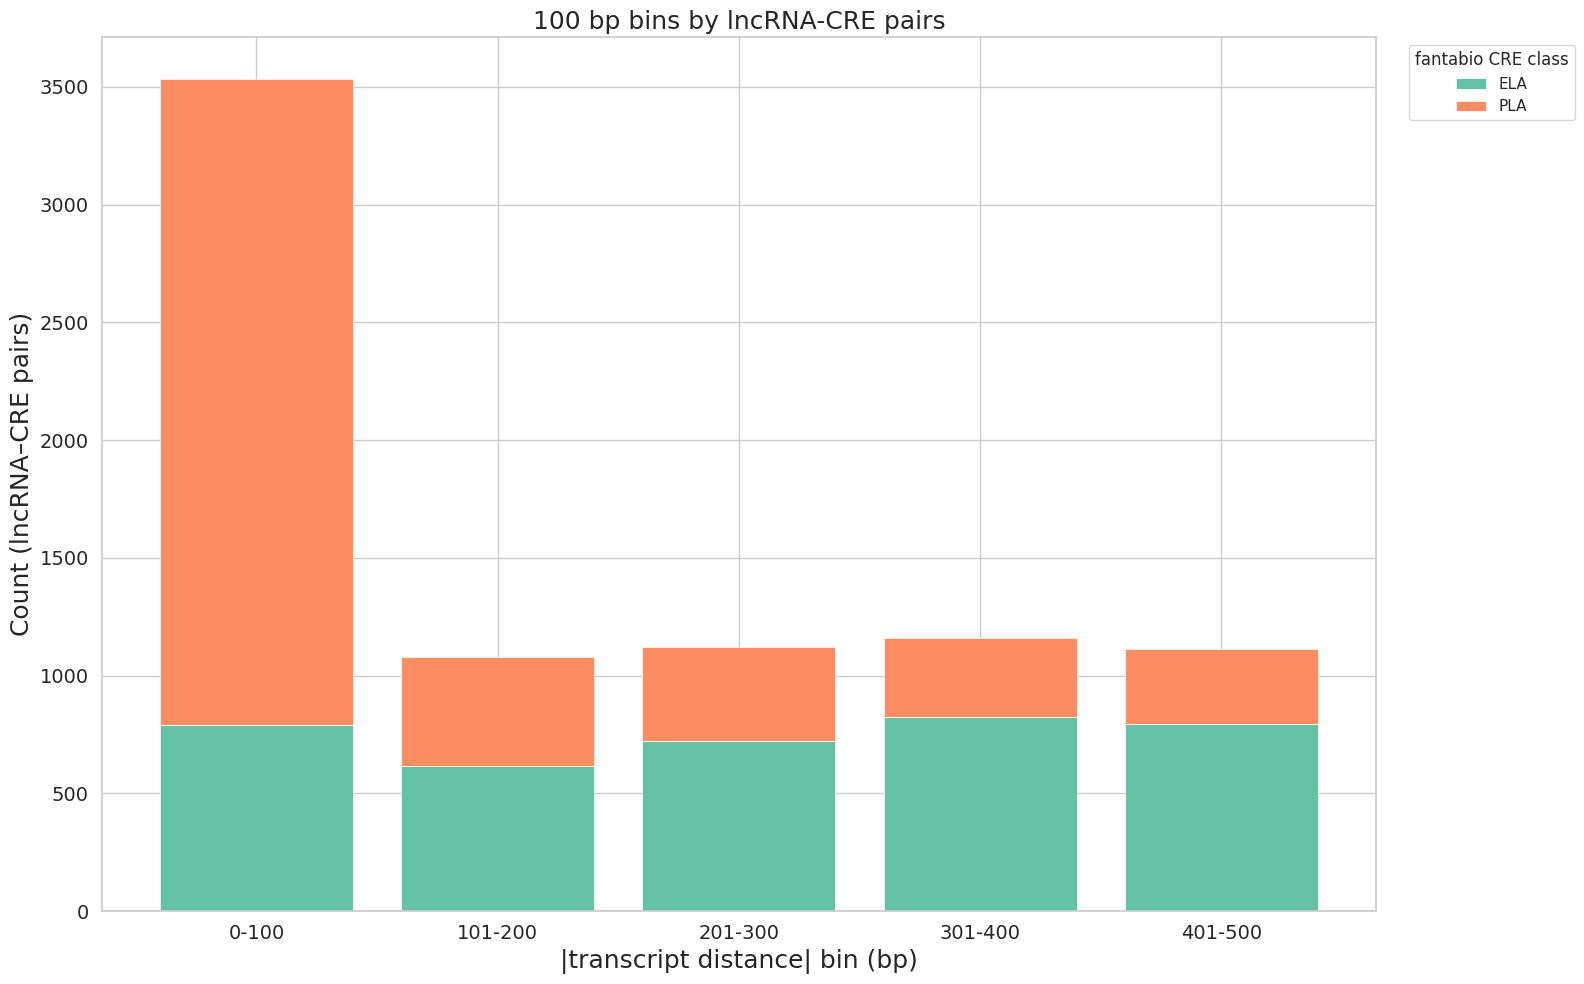

In [16]:
plot_df = bottom5p_lncRNA_fantabio_cre_distance.to_pandas()

# 5 bins: 0-100, 101-200, ..., 401-500
bin_edges = [0, 101, 201, 301, 401, 501]
bin_labels = ["0-100", "101-200", "201-300", "301-400", "401-500"]

plot_df["distance_bin"] = pd.cut(
    plot_df["transcript_distance_abs"],
    bins=bin_edges,
    labels=bin_labels,
    right=False,
    include_lowest=True,
)

count_df = (
    plot_df.groupby(["distance_bin", "fantabio_cre_class"], observed=True)
    .size()
    .to_frame("count")
    .reset_index()
)

pivot_df = (
    count_df.pivot(index="distance_bin", columns="fantabio_cre_class", values="count")
    .fillna(0)
    .astype(int)
    .reindex(bin_labels)
)

classes = pivot_df.columns.tolist()
palette = sns.color_palette("Set2", n_colors=len(classes))
color_map = dict(zip(classes, palette))

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(16, 10))

bottom = np.zeros(len(pivot_df))
x = np.arange(len(pivot_df.index))

for cls in classes:
    heights = pivot_df[cls].to_numpy()
    ax.bar(
        x,
        heights,
        bottom=bottom,
        label=cls,
        color=color_map[cls],
        edgecolor="white",
        linewidth=0.5,
    )
    bottom += heights

ax.set_xticks(x)
ax.set_xticklabels(pivot_df.index, fontsize=14)
ax.set_xlabel("|transcript distance| bin (bp)", fontsize=18)
ax.set_ylabel("Count (lncRNA–CRE pairs)", fontsize=18)
ax.set_title("100 bp bins by lncRNA-CRE pairs", fontsize=18)
ax.legend(title="fantabio CRE class", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.tick_params(axis="y", labelsize=14)

plt.tight_layout()
plt.show()

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## Protein transcript-CRE distance

In [17]:
# Select protein coding transcripts
bottom5p_protein_fantabio = bottom5p_fantabio.filter(
    (pl.col("transcript_type") == "protein_coding")
).sort(
    "HN2",
    descending=True
)


print(f"bottom5p_protein_fantabio ensembl transcript count: {bottom5p_protein_fantabio.select('transcript_id').n_unique()}")
print(f"bottom5p_protein_fantabio transcript-CRE pairs count: {bottom5p_protein_fantabio.select(['transcript_id', 'cre_id']).n_unique()}")
display(bottom5p_protein_fantabio)

bottom5p_protein_fantabio ensembl transcript count: 12063
bottom5p_protein_fantabio transcript-CRE pairs count: 38359


transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000943010.1""",50,98,258,-48,26,35,190,-9,"""MINDY1""","""HGNC:25648""","""protein_coding""","""ENSG00000143409.19""","[""basic"", ""TAGENE""]","""-""",2,null,null,"[""polya_signal"", ""polya_site""]","""ensembl_havana_gene_homo_sapie…","[""ENCODE_tissue""]",1,"""FCHS_24464""","""chr1""",151005761,"""151006352""","""cp1@MINDY1""","[""BC032321""]","""-52""",-98,"[{""EH38E1383980"",""pELS""}, {""EH38E2837214"",""pELS""}, {""EH38E2837215"",""PLS""}]","[{""ESR1"",1408,[{""SRX7427512"",1408}, {""SRX1995230"",1385}, … {""SRX371473"",524}]}, {""ASCL1"",1400,[{""SRX8670127"",1400}, {""SRX8670130"",1256}, {""SRX8670128"",994}]}, … {""ZNF263"",607,[{""SRX150656"",607}]}]","[{""HS_00011826"",""Fetal Intestine Small"",""Small intestine"",""Intestine"",""SVM""}]",null,null,0.739726,"""ELA""","""255,202,74""","""yellow"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000540567.1""",15,266,125,-251,8,175,68,-167,"""ATG16L2""","""HGNC:25464""","""protein_coding""","""ENSG00000168010.12""","[""mRNA_start_NF"", ""cds_start_NF""]","""+""",2,null,null,null,"""ensembl_havana_gene_homo_sapie…",null,0,"""FCHS_76431""","""chr11""",72814491,"""72815201""","""FCHS_76431""","[""LF369278"", ""MA604855""]","""0""",-59,"[{""EH38E2971315"",""pELS""}, {""EH38E4041623"",""pELS""}, {""EH38E4041624"",""pELS""}]","[{""CTCF"",3271,[{""SRX10976007"",3271}, {""SRX10976001"",3232}, … {""SRX103004"",532}]}, {""ZNF687"",1841,[{""SRX10478566"",1841}, {""SRX10478565"",521}]}, … {""INTS12"",502,[{""SRX1711343"",502}]}]","[{""HS_00157550"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, {""HS_00157551"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}]","[{""hg19::chr11:72525686..72525719,-;hg_121223.1"",""hg_121223.1""}, {""hg19::chr11:72526037..72526046,+;hg_115767.1"",""hg_115767.1""}]",null,-0.563197,"""PLA""","""0,0,102""","""dark_blue"""


In [18]:
# このデータフレームの行数 = protein transcript - CRE pair count になる
bottom5p_protein_fantabio_cre_distance = bottom5p_protein_fantabio.select(
    "transcript_id",
    "cre_id",
    "cre_name",
    "fantabio_cre_class",
    "transcript_distance"
).with_columns(
    pl.col("transcript_distance").abs().alias("transcript_distance_abs") # Point: 絶対値に変換
).unique()

display(bottom5p_protein_fantabio_cre_distance)

transcript_id,cre_id,cre_name,fantabio_cre_class,transcript_distance,transcript_distance_abs
str,str,str,str,i64,i64
"""ENST00000705652.1""","""FCHS_287019""","""cp14@SLMAP""","""ELA""",-81,81
…,…,…,…,…,…
"""ENST00000556036.6""","""FCHS_122143""","""cp3@FANCM""","""PLA""",0,0


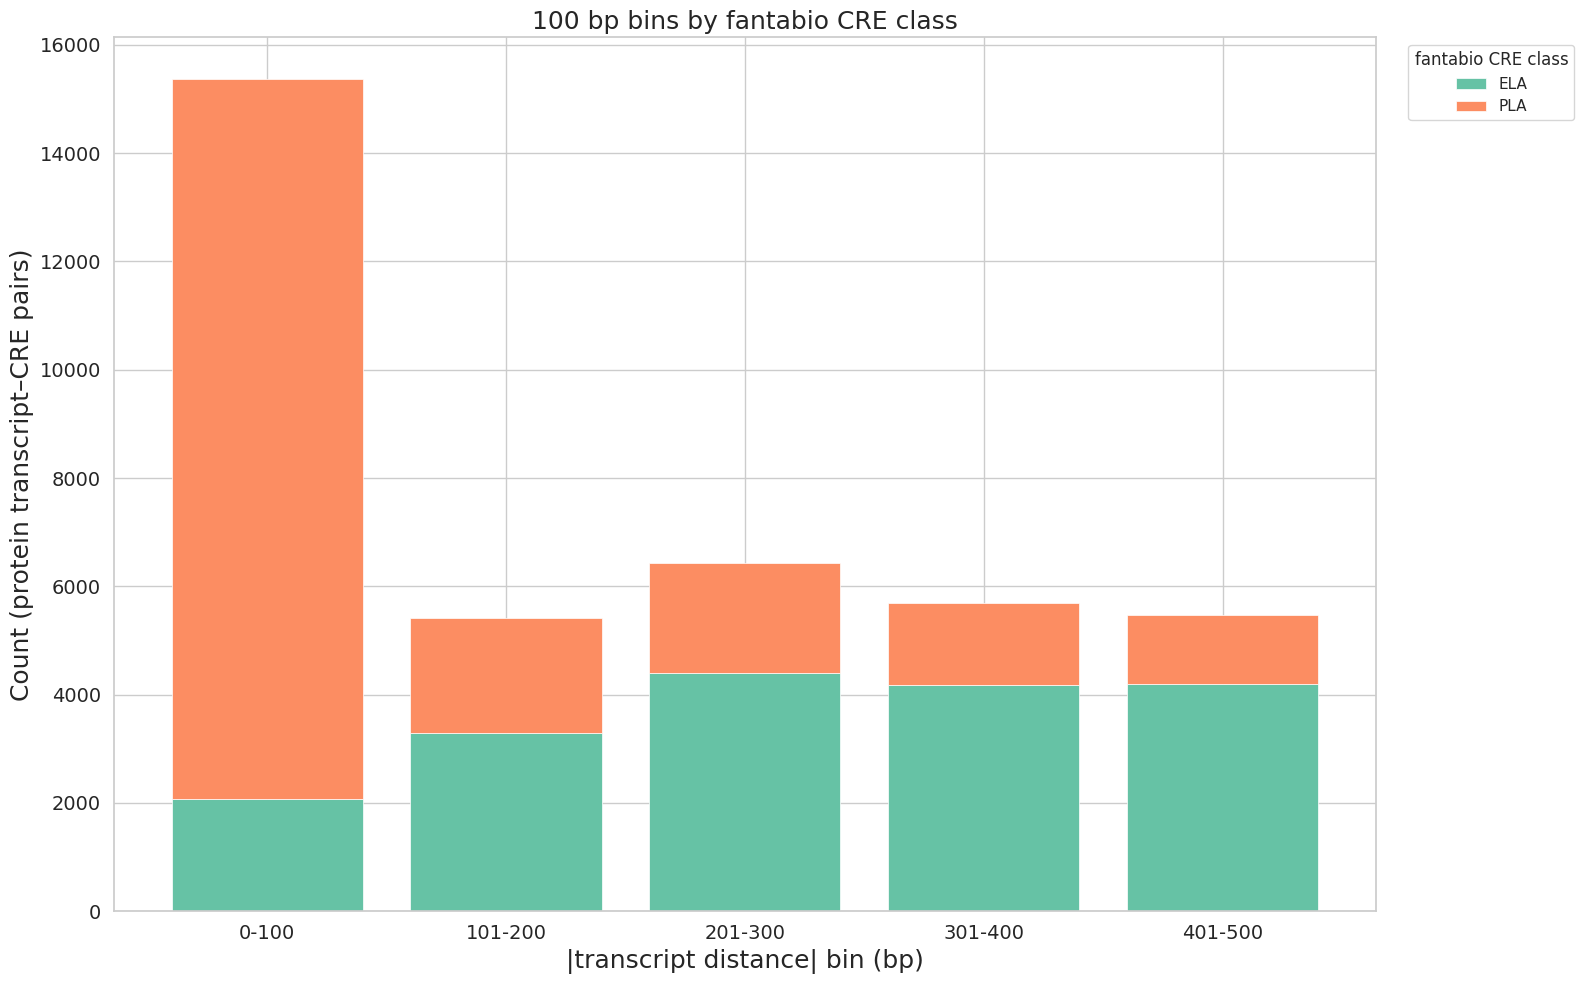

In [19]:
plot_df = bottom5p_protein_fantabio_cre_distance.to_pandas()

# 5 bins: 0-100, 101-200, ..., 401-500
bin_edges = [0, 101, 201, 301, 401, 501]
bin_labels = ["0-100", "101-200", "201-300", "301-400", "401-500"]

plot_df["distance_bin"] = pd.cut(
    plot_df["transcript_distance_abs"],
    bins=bin_edges,
    labels=bin_labels,
    right=False,
    include_lowest=True,
)

count_df = (
    plot_df.groupby(["distance_bin", "fantabio_cre_class"], observed=True)
    .size()
    .to_frame("count")
    .reset_index()
)

pivot_df = (
    count_df.pivot(index="distance_bin", columns="fantabio_cre_class", values="count")
    .fillna(0)
    .astype(int)
    .reindex(bin_labels)
)

classes = pivot_df.columns.tolist()
palette = sns.color_palette("Set2", n_colors=len(classes))
color_map = dict(zip(classes, palette))

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(16, 10))

bottom = np.zeros(len(pivot_df))
x = np.arange(len(pivot_df.index))

for cls in classes:
    heights = pivot_df[cls].to_numpy()
    ax.bar(
        x,
        heights,
        bottom=bottom,
        label=cls,
        color=color_map[cls],
        edgecolor="white",
        linewidth=0.5,
    )
    bottom += heights

ax.set_xticks(x)
ax.set_xticklabels(pivot_df.index, fontsize=14)
ax.set_xlabel("|transcript distance| bin (bp)", fontsize=18)
ax.set_ylabel("Count (protein transcript–CRE pairs)", fontsize=18)
ax.set_title("100 bp bins by fantabio CRE class", fontsize=18)
ax.legend(title="fantabio CRE class", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.tick_params(axis="y", labelsize=14)

plt.tight_layout()
plt.show()

&nbsp;

&nbsp;

&nbsp;

## Other transcripts (except lncRNA and protein-coding) - CREs

In [20]:
# Select other transcripts
bottom5p_other_fantabio = bottom5p_fantabio.filter(
    (pl.col("transcript_type") != "lncRNA") & (pl.col("transcript_type") != "protein_coding")
).sort(
    "HN2",
    descending=True
)


print(f"bottom5p_other_fantabio ensembl transcript count: {bottom5p_other_fantabio.select('transcript_id').n_unique()}")
print(f"bottom5p_other_fantabio transcript-CRE pairs count: {bottom5p_other_fantabio.select(['transcript_id', 'cre_id']).n_unique()}")
display(bottom5p_other_fantabio)

bottom5p_other_fantabio ensembl transcript count: 7469
bottom5p_other_fantabio transcript-CRE pairs count: 20595


transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000680987.1""",73,121,212,-48,50,60,141,-10,"""SMPD4""","""HGNC:32949""","""nonsense_mediated_decay""","""ENSG00000136699.21""","[""RNA_Seq_supported_only""]","""-""",1,null,null,null,"""ensembl_havana_gene_homo_sapie…","[""RNA-Seq supported only""]",1,"""FCHS_232997""","""chr2""",130180773,"""130181187""","""cp5@SMPD4""","[""ENST00000441135.1""]","""-355""",-412,"[{""EH38E2032757"",""pELS""}, {""EH38E4230493"",""pELS""}]","[{""BCL6"",1775,[{""SRX3135177"",1775}, {""SRX3135176"",1409}]}, {""CTCF"",1143,[{""SRX12008351"",1143}, {""SRX13551281"",1134}, {""SRX12008350"",938}]}, {""TP63"",1042,[{""SRX19885676"",1042}]}]","[{""HS_00030649"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}, {""HS_00030650"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, … {""HS_00030652"",""Gastric"",""Stomach"",""Stomach"",""SVM""}]",null,null,0.684211,"""ELA""","""255,202,74""","""yellow"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000549545.1""",11,265,130,-254,8,174,69,-166,"""COQ10A""","""HGNC:26515""","""retained_intron""","""ENSG00000135469.15""",[],"""+""",0,null,null,null,"""ensembl_havana_gene_homo_sapie…",null,0,"""FCHS_96252""","""chr12""",56268140,"""56268446""","""cp6@COQ10A""","[""ENST00000549545.1""]","""-23""",-23,"[{""EH38E4064794"",""pELS""}]",null,"[{""HS_00173371"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, {""HS_02053667"",""Thyroid Gland"",""Thyroid gland"",""Others"",""gkmSVM""}]",null,null,-0.368421,"""ELA""","""255,202,74""","""yellow"""


In [21]:
# このデータフレームの行数 = protein transcript - CRE pair count になる
bottom5p_other_fantabio_cre_distance = bottom5p_other_fantabio.select(
    "transcript_id",
    "cre_id",
    "cre_name",
    "fantabio_cre_class",
    "transcript_distance"
).with_columns(
    pl.col("transcript_distance").abs().alias("transcript_distance_abs") # Point: 絶対値に変換
).unique()

display(bottom5p_other_fantabio_cre_distance)

transcript_id,cre_id,cre_name,fantabio_cre_class,transcript_distance,transcript_distance_abs
str,str,str,str,i64,i64
"""ENST00000468735.6""","""FCHS_283466""","""cp2@SEC22C""","""ELA""",-481,481
…,…,…,…,…,…
"""ENST00000476298.2""","""FCHS_168983""","""cp1@B9D1,cp4@MAPK7""","""PLA""",-242,242


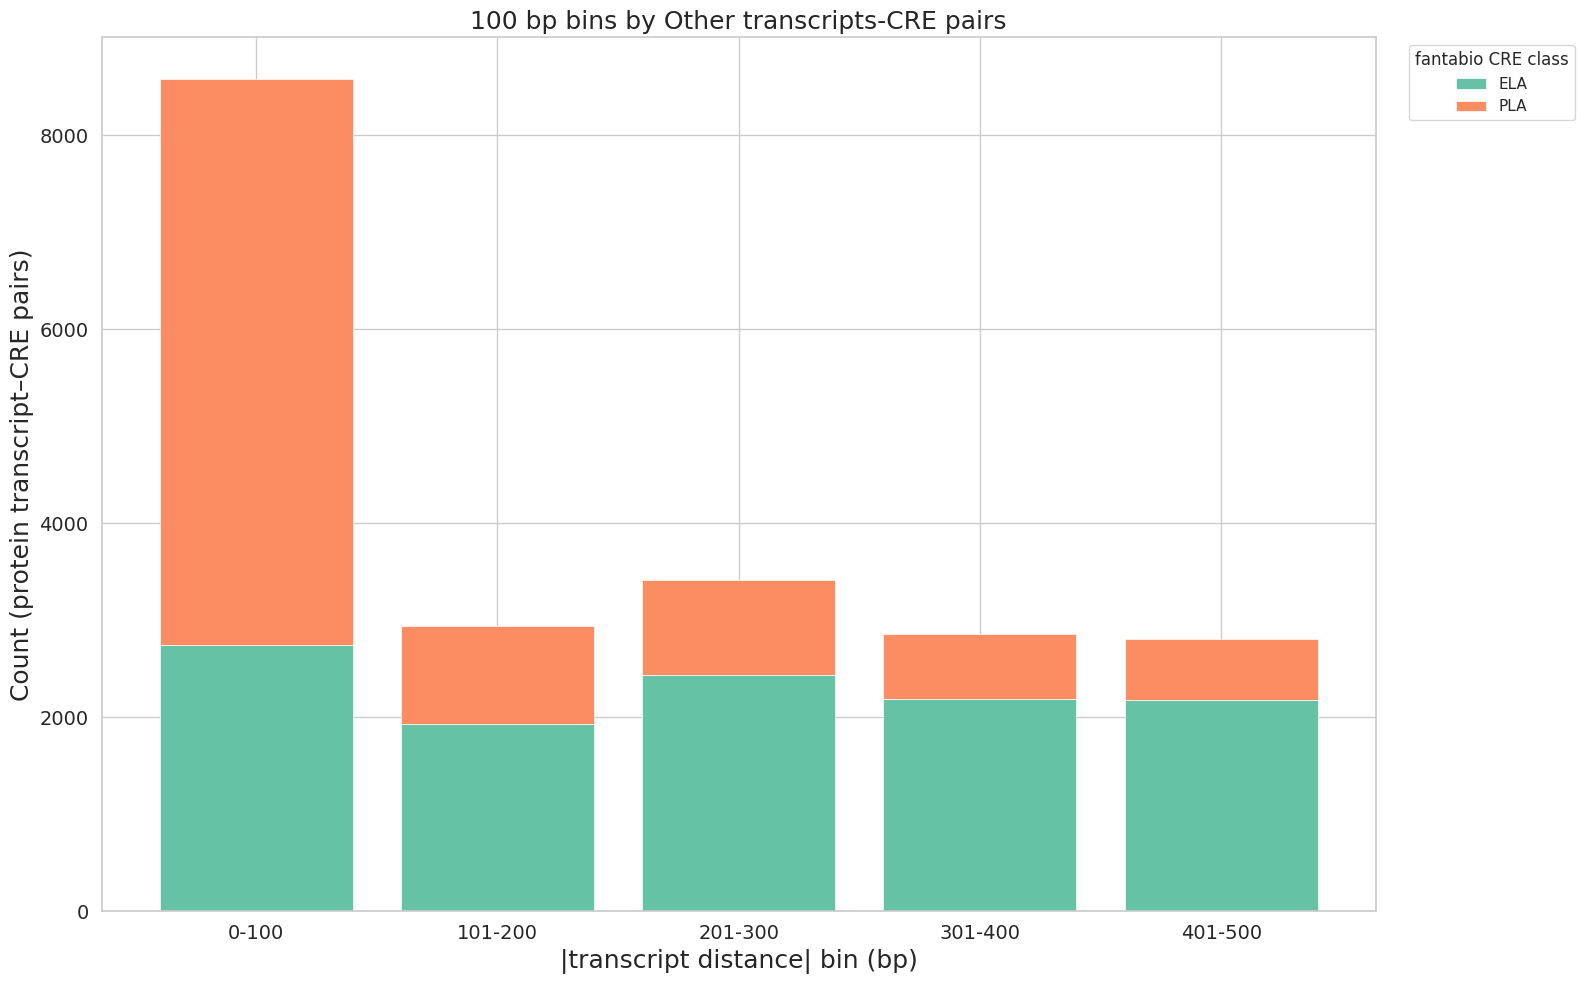

In [22]:
plot_df = bottom5p_other_fantabio_cre_distance.to_pandas()

# 5 bins: 0-100, 101-200, ..., 401-500
bin_edges = [0, 101, 201, 301, 401, 501]
bin_labels = ["0-100", "101-200", "201-300", "301-400", "401-500"]

plot_df["distance_bin"] = pd.cut(
    plot_df["transcript_distance_abs"],
    bins=bin_edges,
    labels=bin_labels,
    right=False,
    include_lowest=True,
)

count_df = (
    plot_df.groupby(["distance_bin", "fantabio_cre_class"], observed=True)
    .size()
    .to_frame("count")
    .reset_index()
)

pivot_df = (
    count_df.pivot(index="distance_bin", columns="fantabio_cre_class", values="count")
    .fillna(0)
    .astype(int)
    .reindex(bin_labels)
)

classes = pivot_df.columns.tolist()
palette = sns.color_palette("Set2", n_colors=len(classes))
color_map = dict(zip(classes, palette))

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(16, 10))

bottom = np.zeros(len(pivot_df))
x = np.arange(len(pivot_df.index))

for cls in classes:
    heights = pivot_df[cls].to_numpy()
    ax.bar(
        x,
        heights,
        bottom=bottom,
        label=cls,
        color=color_map[cls],
        edgecolor="white",
        linewidth=0.5,
    )
    bottom += heights

ax.set_xticks(x)
ax.set_xticklabels(pivot_df.index, fontsize=14)
ax.set_xlabel("|transcript distance| bin (bp)", fontsize=18)
ax.set_ylabel("Count (protein transcript–CRE pairs)", fontsize=18)
ax.set_title("100 bp bins by Other transcripts-CRE pairs", fontsize=18)
ax.legend(title="fantabio CRE class", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.tick_params(axis="y", labelsize=14)

plt.tight_layout()
plt.show()

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## Upsetplot

- lncRNA-CRE pairs, protein-coding transcript-CRE pairs, other transcript-CRE pairs で共通している CREを表現する

In [23]:
cre_contents = {
    "lncRNA proximal CREs (PLA)": bottom5p_lncRNA_fantabio.filter(pl.col("fantabio_cre_class") == "PLA").select("cre_id").unique().to_series().to_list(),
    "protein-coding proximal CREs (PLA)": bottom5p_protein_fantabio.filter(pl.col("fantabio_cre_class") == "PLA").select("cre_id").unique().to_series().to_list(),
    "lncRNA proximal CREs (ELA)": bottom5p_lncRNA_fantabio.filter(pl.col("fantabio_cre_class") == "ELA").select("cre_id").unique().to_series().to_list(),
    "protein-coding proximal CREs (ELA)": bottom5p_protein_fantabio.filter(pl.col("fantabio_cre_class") == "ELA").select("cre_id").unique().to_series().to_list(),
    # "other transcript proximal CREs": bottom5p_other_fantabio.select("cre_id").unique().to_series().to_list()
}

upset_data = from_contents(cre_contents)

upset_data.to_csv(
    f"../../out/fantabio/upsetplot/bottom5p_transcript_upset_data_v{Execute_date}.tsv",
    index=True,
    sep="\t"
)

display(upset_data)

/usr/local/lib/python3.13/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)


id
lncRNA proximal CREs (PLA) protein-coding proximal CREs (PLA) lncRNA proximal CREs (ELA) protein-coding proximal CREs (ELA)             
True                       False                              False                      False                               FCHS_439916
                                                                                         False                               FCHS_185905
                                                                                         False                               FCHS_213081
                                                                                         False                               FCHS_267663
                           True                               False                      False                               FCHS_283823
...                                                                                                                                  ...
False                      False                              False                      True                                 FCHS_19326
                                                                                         True                                FCHS_107020
                                                                                         True                                FCHS_242138
                                                                                         True                                FCHS_181647
                                                                                         True                                FCHS_180064

[26162 rows x 1 columns]

/usr/local/lib/python3.13/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/usr/local/lib/python3.13/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example,

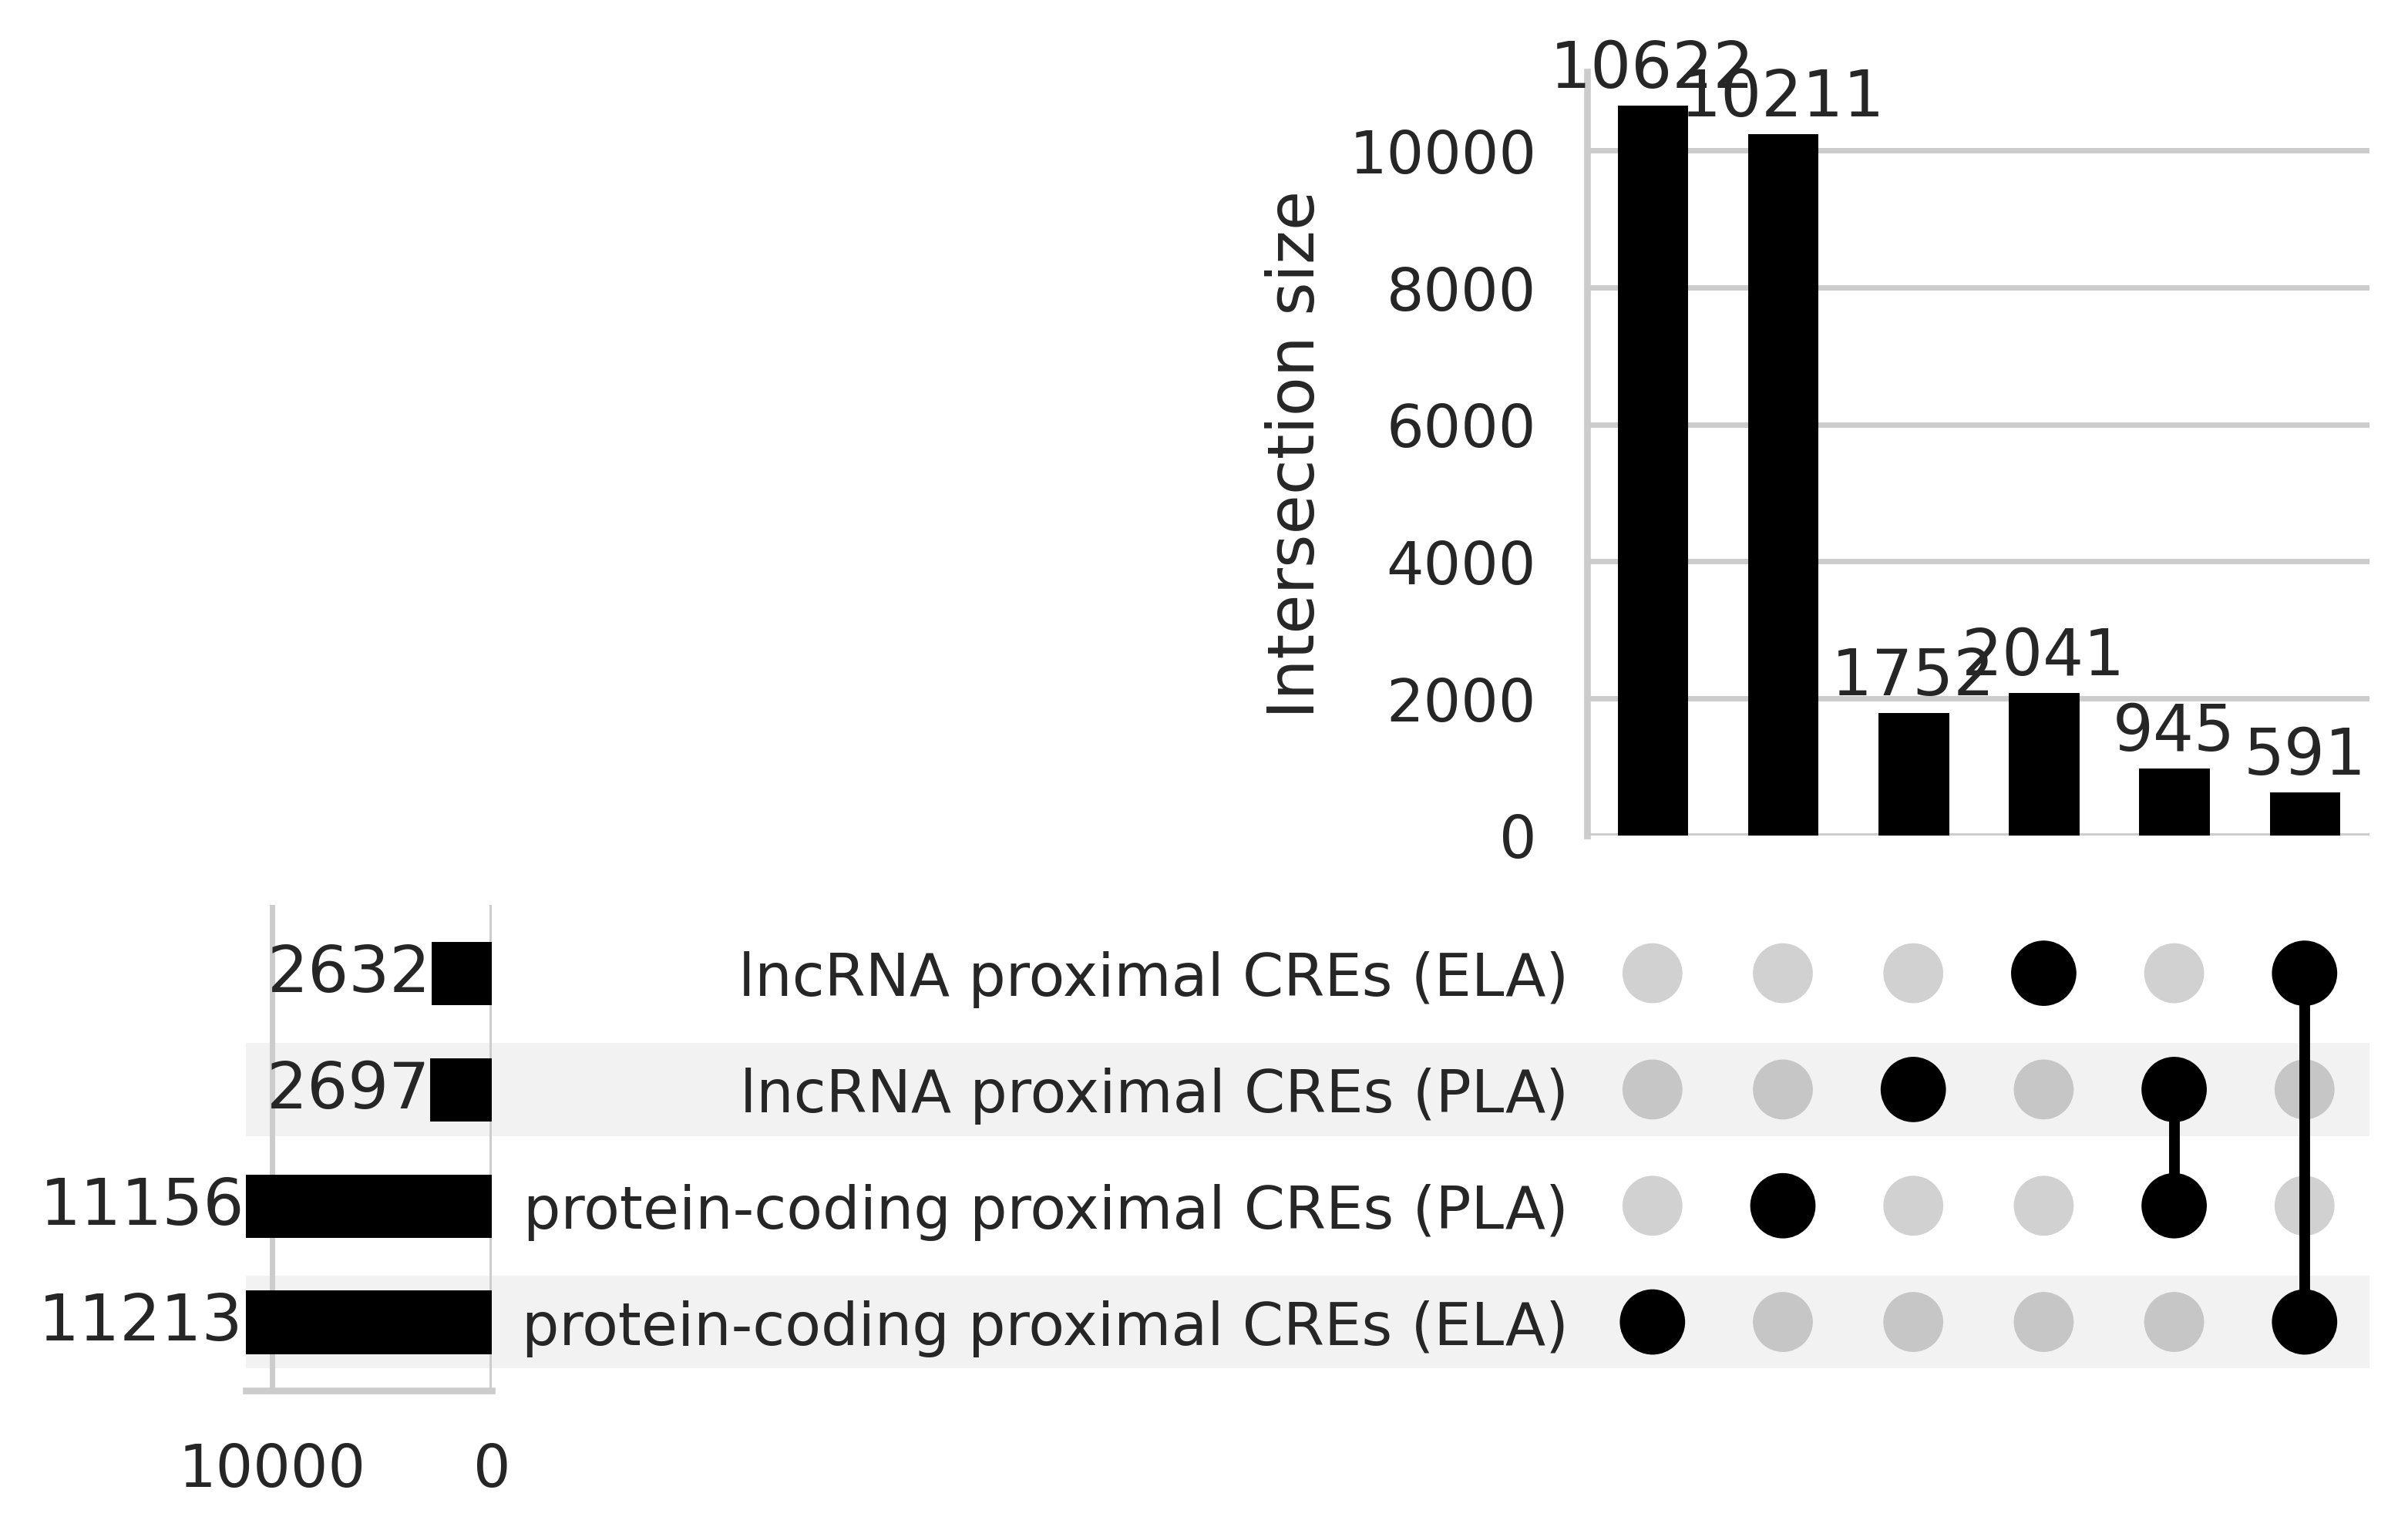

In [24]:
upset_plot = UpSet(
    upset_data,
    orientation='horizontal',
    show_counts="{:d}",
    subset_size='count',
    include_empty_subsets = False
)

fig = plt.figure(figsize=(14, 8), dpi=500)
upset_plot.plot(fig=fig)
plt.show()